# p2.5: One network or two - the student's policy and value (11/24/26)

*Part of phase 2: `p2_summary.ipynb` connects this notebook with p2.1-p2.4.*

The student's network had one trunk and two heads: a **policy** head (which move to play; also the order in which
AND-OR tries its options) and a **value** head (moves to go; the two-mode student's flat planning compares its top
moves by it). Both were trained on the sum of the two losses, so the shared trunk learned from both. The usual case
for sharing is that an extra target helps the main task. This notebook asks whether it does here, and what the
student would look like as **two networks** - one that learns to *choose*, one that learns to *judge*.

Everything here starts from the same data: round 1 of AND-OR's apprentice (plain AND-OR's 2,966 solved attempts on
1,000 pool puzzles: 68,039 labelled boards), with no dest head (removed earlier on 11/24, `p2_summary` section 7).

| run | trained on | |
|---|---|---|
| `gamma0.07_free_nodest` | moves + distances, one trunk | the **shared** network (the start until this notebook) |
| `gamma0.07_free_novalue` | moves only | the **policy network** |
| `gamma0.07_free_valueonly` | distances only | the **value network** |
| `..._nodest_i1`, `..._novalue_i1` | as the first two, other initial weights | the run-to-run check |

`experiments/separate_value.py` writes the tables read here (`models/summary/separate_value/`); the two-mode
sessions are `experiments/planner_session.py --lean` runs.

In [1]:
import json
import os
import sys
sys.path.insert(0, "..")
sys.path.insert(0, os.path.join("..", "experiments"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import fit_memory as fm
from rushhour import human_data as hd, paths

SV = os.path.join(paths.MODELS, "summary", "separate_value")
INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
COLORS = {"people": INK, "shared": "#e6550d", "policy only": "#2a78d6", "shared, other weights": "#fdae6b",
          "policy only, other weights": "#9ecae1", "value only": "#b5b4ad",
          "shared, seed 0": "#e6550d", "shared, seed 1": "#fdae6b", "separate, seed 0": "#2a78d6",
          "separate, seed 1": "#9ecae1"}
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


curves = pd.read_csv(os.path.join(SV, "curves.csv"))
startfit = pd.read_csv(os.path.join(SV, "startfit.csv"))
quality = pd.read_csv(os.path.join(SV, "quality.csv"))
split = pd.read_csv(os.path.join(SV, "split.csv"))
rules = pd.read_csv(os.path.join(SV, "rules.csv"))
SESSIONS = {"shared, seed 0": "lean_people_all_m10_ao_nodest_refit",
            "shared, seed 1": "lean_people_all_m10_ao_nodest_refit_seed1",
            "separate, seed 0": "lean_people_all_m10_ao_separate",
            "separate, seed 1": "lean_people_all_m10_ao_separate_seed1"}
STAGES = [(1, 9), (10, 27), (28, 45), (46, 72)]
LABELS = [f"{a}-{b}" for a, b in STAGES]

## 1. Pretraining without the value loss

The policy's agreement with AND-OR's moves on held-out puzzles, epoch by epoch, and each run's epochs fitted to
people's first 10 trials as the start always is (`rushhour.surrender`: by intuition on pool puzzles of people's
lengths, giving up scaled to fit).

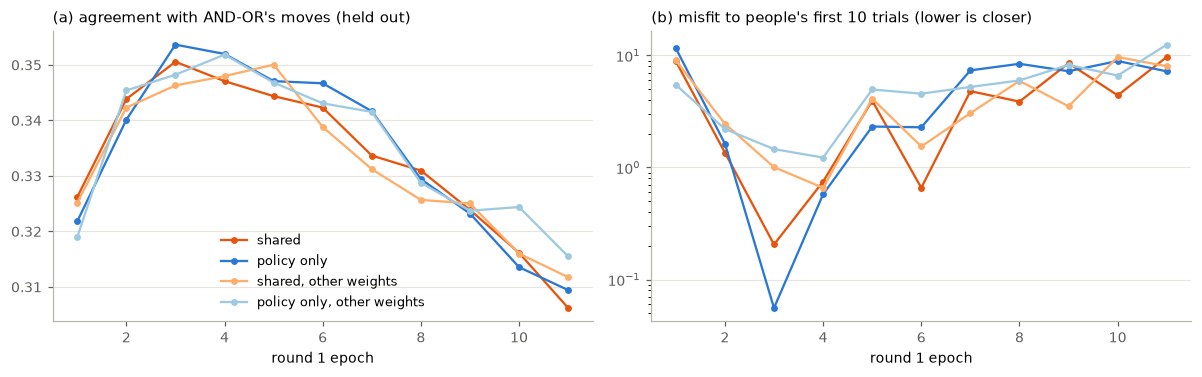

,epoch,scale,solved,moves / optimal,misfit
run,,,,,
policy only,3,0.35,87.3%,2.72,0.06
"policy only, other weights",4,0.45,88.4%,2.59,1.23
shared,3,0.35,87.9%,2.69,0.21
"shared, other weights",4,0.40,88.1%,2.63,0.66


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for run in ["shared", "policy only", "shared, other weights", "policy only, other weights"]:
    d = curves[curves.run == run]
    axes[0].plot(d.epoch, d.agreement, "o-", ms=3.5, color=COLORS[run], label=run)
    f = startfit[startfit.run == run]
    axes[1].plot(f.epoch, f.misfit, "o-", ms=3.5, color=COLORS[run], label=run)
axes[0].set_title("(a) agreement with AND-OR's moves (held out)")
axes[0].set_xlabel("round 1 epoch")
axes[1].set_title("(b) misfit to people's first 10 trials (lower is closer)")
axes[1].set_xlabel("round 1 epoch")
axes[1].set_yscale("log")
axes[0].legend()
for a in axes:
    tidy(a)
plt.tight_layout()
plt.show()
best = startfit.loc[startfit.groupby("run").misfit.idxmin()].set_index("run")
best[["epoch", "scale", "solved", "moves / optimal", "misfit"]].style.format(
    {"scale": "{:.2f}", "solved": "{:.1%}", "moves / optimal": "{:.2f}", "misfit": "{:.2f}"})

- **The value loss doesn't help the policy learn.** With or without it, agreement climbs to about 35% by epoch 3-4
  and then falls as the policy overfits AND-OR's attempts; the curves differ by about 0.01, as much as two runs of
  the same setting do.
- **Every run matches people's start at the same point**: epoch 3 (or 4, with the other initial weights) at a
  giving-up scale of 0.30-0.45. The policy-only run's epoch 3 fits best of all (misfit 0.06, against 0.21 for the
  shared run), but the other-weights runs swap the order (0.66 shared, 1.2 policy only at epoch 4): the start fit
  can't tell the two settings apart.
- **Why the extra target doesn't help here**: data isn't scarce (68,039 boards for a network of 1.16 million weights),
  and the distance target - the moves AND-OR still took, about twice the optimal - mostly restates the blocking
  structure the move targets already teach.

## 2. The value network alone

A value network trained on the distances only, against the shared network's value head, on boards from people's
70 layouts (40 each) with their true distances.

In [3]:
quality.style.format({"spearman with true distance": "{:.3f}", "estimate / true": "{:.2f}",
                      "mean abs error": "{:.1f}"}).hide(axis="index")

network,spearman with true distance,estimate / true,mean abs error
shared (its value head),0.852,1.93,5.9
"value only, epoch 1",0.829,2.05,6.4
"value only, epoch 2",0.821,3.00,11.1
"value only, epoch 3",0.866,1.81,6.0
"value only, epoch 5",0.851,2.18,7.1
"value only, epoch 8",0.861,2.22,8.1
"value only, epoch 11",0.874,1.82,6.3


At epoch 3 - the start's epoch - the value network ranks boards by distance as well as the shared head does (rank
correlation 0.87 against 0.85), on the same inflated scale (about 1.8-1.9 x the true distance: the target is AND-OR's
moves left, not the optimal). It is taken at epoch 3, with the policy network.

## 3. The two-mode student with two networks

The two-mode session (current weights: AND-OR 18%, flat 6% → 18%; giving up x 0.35) from each start, two seeds each.
With two networks each learns only its own targets from every block: the policy network the moves, the value network
the distances.

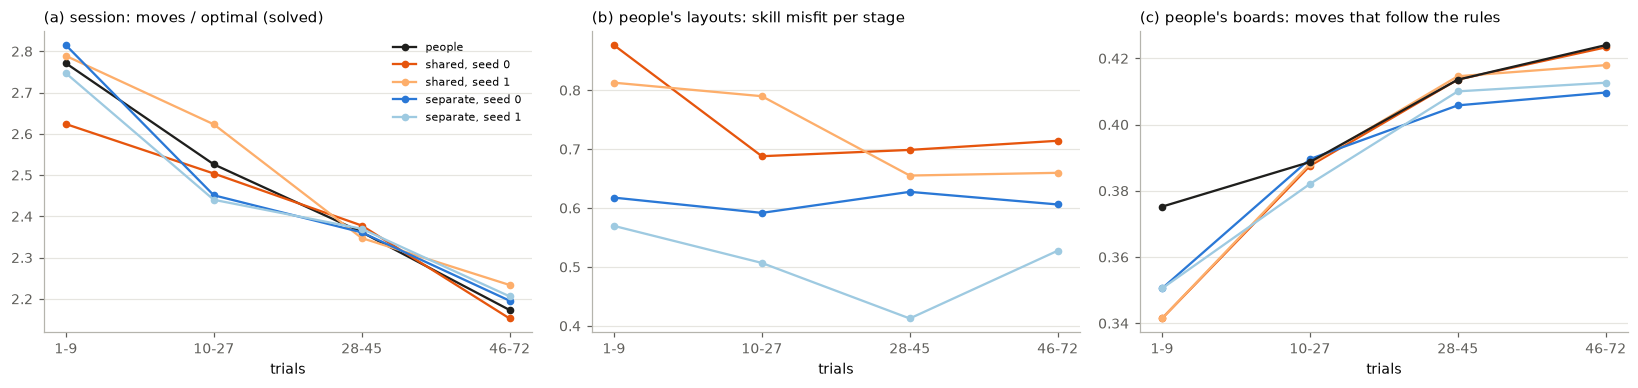

people: gain 0.60; on their layouts 2.32 -> 1.93


,session gain,layouts: start moves / optimal,layouts: after 54,"skill misfit, total","revisit misfit, total"
"shared, seed 0",0.47,3.65,2.89,2.98,0.34
"shared, seed 1",0.56,3.59,2.86,2.92,0.30
"separate, seed 0",0.62,3.41,2.84,2.44,0.27
"separate, seed 1",0.54,3.36,2.76,2.02,0.29


In [4]:
def stage_of(x):
    return next(l for (a, b), l in zip(STAGES, LABELS) if a <= x <= b)


rows = {}
p = hd.trials()
p = p[p.trial <= 72].assign(ratio=lambda t: t.moves / t.distance)
for st, g in p.groupby(p.trial.map(stage_of)):
    w = g[g.solved]
    rows[("people", st)] = w.ratio.groupby(w.subject).mean().mean()
gains = {}
for name, run in SESSIONS.items():
    d = json.load(open(os.path.join(paths.SESSIONS, run, "no_teacher", "sessions.json")))
    e = pd.DataFrame([dict(x, subject=s) for s, r in d.items() for x in r]).assign(ratio=lambda t: t.moves / t.distance)
    for st, g in e.groupby(e.trial.map(stage_of)):
        w = g[g.solved]
        rows[(name, st)] = w.ratio.groupby(w.subject).mean().mean()
session = pd.Series(rows).unstack()[LABELS]
session["gain"] = session["1-9"] - session["46-72"]

fits = {}
for name, run in SESSIONS.items():
    o, people = fm.summarize_learning(pd.read_csv(os.path.join(paths.MODELS, "summary", f"lean_snapshots_{run}.csv")),
                                      fm.SNAP_STAGES)
    fits[name] = o[[r.snapshot == fm.SNAP_OF[r.stage] for r in o.itertuples()]].set_index("stage")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for name in ["people"] + list(SESSIONS):
    axes[0].plot(range(4), session.loc[name, LABELS], "o-", ms=4, color=COLORS[name], label=name)
    if name != "people":
        axes[1].plot(range(4), fits[name]["skill misfit"], "o-", ms=4, color=COLORS[name], label=name)
        r = rules[rules.who == name].set_index("stage").loc[list(fm.SNAP_STAGES), "follows"]
        axes[2].plot(range(4), r, "o-", ms=4, color=COLORS[name], label=name)
r = rules[rules.who == "people"].set_index("stage").loc[list(fm.SNAP_STAGES), "follows"]
axes[2].plot(range(4), r, "o-", ms=4, color=INK, label="people")
axes[0].set_title("(a) session: moves / optimal (solved)")
axes[1].set_title("(b) people's layouts: skill misfit per stage")
axes[2].set_title("(c) people's boards: moves that follow the rules")
for a in axes:
    a.set_xticks(range(4), LABELS)
    a.set_xlabel("trials")
    tidy(a)
axes[0].legend(fontsize=7.5)
plt.tight_layout()
plt.show()
summary = pd.DataFrame({"session gain": session.loc[list(SESSIONS), "gain"],
                        "layouts: start moves / optimal": [fits[n]["moves / optimal"].iloc[0] for n in SESSIONS],
                        "layouts: after 54": [fits[n]["moves / optimal"].iloc[-1] for n in SESSIONS],
                        "skill misfit, total": [fits[n]["skill misfit"].sum() for n in SESSIONS],
                        "revisit misfit, total": [fits[n]["revisit misfit"].sum() for n in SESSIONS]})
print(f"people: gain {session.loc['people', 'gain']:.2f}; on their layouts {people['moves / optimal'].iloc[0]:.2f} -> "
      f"{people['moves / optimal'].iloc[-1]:.2f}")
summary.style.format("{:.2f}")

- **Learning in the session is the same.** The separate networks gain 0.62 and 0.54 moves / optimal over the session
  (seeds 0 and 1), the shared network 0.47 and 0.56; people 0.60. The two seeds of one setting differ as much as the
  two settings do.
- **On people's own layouts the separate networks fit somewhat better** (b): total skill misfit 2.44 and 2.02
  against 2.98 and 2.92, and fewer excess revisits. A good part of that is the start (stage 1-9: 0.62 and 0.57 against
  0.88 and 0.81), which is within how much one start's misfit moves between replays (section 4); after the start the
  separate networks are 0.05-0.25 better per stage at both seeds - consistent, and about as large as that noise
  (0.09 on average), so suggestive rather than established. Both are
  still far from people there (2.32 → 1.93): the mid-puzzle gap stays.
- **Rule-following is the same** (c, `p2.4_rules`): 35% → 41% of the policy's probability on the rule moves, against
  34% → 42% for the shared network and people's 37.5% → 42.4%.

## 4. Where the difference comes from

The separate start differs from the shared one in two ways at once: its policy network was trained without the value
loss, and its value network is separate. Every pairing of policy and value network as the two-mode student's start on
people's layouts (16 attempts per layout; against people's trials 1-9), and each policy alone by intuition; the
policies with other initial weights at their best-fitting epoch (4).

In [5]:
split["kind"] = split.value
table = split.pivot(index="policy", columns="value", values="skill misfit")
table2 = split.pivot(index="policy", columns="value", values="moves / optimal")
both = pd.concat({"skill misfit": table, "moves / optimal": table2}, axis=1)
both.style.format("{:.2f}")

The same starts replayed with other random draws (`split_replay.csv`, an earlier run of the same six
starts): how much a start's misfit moves by chance alone.

In [6]:
replay = pd.read_csv(os.path.join(SV, "split_replay.csv")).set_index(["policy", "value"])["skill misfit"]
now = split.set_index(["policy", "value"])["skill misfit"]
j = pd.concat({"first replay": replay, "second replay": now}, axis=1).dropna()
j["difference"] = j["second replay"] - j["first replay"]
print(f"mean |difference| {j.difference.abs().mean():.3f}")
j.style.format("{:+.2f}", subset=["difference"]).format("{:.2f}", subset=["first replay", "second replay"])

mean |difference| 0.089


- **Neither half of the split changes how human-like the start is.** In this replay the shared policy does as well
  as the policy-only one (0.62-0.67 against 0.60-0.75), and swapping value networks moves the misfit either way by up
  to 0.14. An earlier replay of the same six starts had suggested the policy trained without the value loss fits
  better (0.61-0.62 against 0.73-0.75, and 0.93 against 1.13 by intuition); this one reverses half of that. The same
  start replayed (70 layouts x 16 attempts) moves by 0.09 on average and up to 0.14 - as much as any difference
  between the settings.
- **One more epoch of training matters more than the value loss.** The other-weights runs, taken at epoch 4 (their
  best fit on pool puzzles), fit people's layouts better than either epoch-3 run with every value network (0.42-0.54;
  3.2-3.3 moves / optimal against 3.4-3.5) - and again shared and policy-only alike.
- **So the separate networks are as human-like as the shared one, not more**: the earlier sign of a better policy was
  replay noise, and the session comparison above (a small, consistent edge after the start) can't be told from
  chance with two seeds.

## 5. The student now

**The student is two networks** (`paths.START` = `models/apprentice/separate/round1_epoch03.pt`, since 11/24): the
policy network (`gamma0.07_free_novalue`, epoch 3) and the value network (`gamma0.07_free_valueonly`, epoch 3),
saved together (`PolicyAgent.value_agent`). In a session each learns only its own targets; the two-mode student's
flat planning reads the value network, and everything else - intuition, AND-OR's ordering - reads the policy
network. Giving up stays at 0.35 x people's rates. The one-network start is `paths.SHARED_START` / `spec.SHARED`.

**Why**: the split costs nothing measurable - learning in pretraining and in the session, the start, rule-following
and the fit to people's own layouts are all as good (no difference beyond the noise of seeds and replays) - and it
makes the model easier to explain: one network learns to choose, the other to judge, and each can be studied on its
own.

**Caveats**
- Two seeds per session setting and two initial-weight runs per pretraining setting: enough to see that the two
  settings are close, not to rank them finely.
- The value networks' shared and separate versions were not retrained from other initial weights.
- Phase 1's fitted values (the multiplier, hindsight, bayes4's θ) were fitted with earlier starts and are kept.